# Tarea 1 – Parte 2: Modelado y Clasificación

## 1. Línea de base Zero Shot (sin fine-tuning)

In [2]:
import pandas as pd
import numpy as np 
import torch
import matplotlib.pyplot as plt
from transformers import pipeline, AutoModelForCausalLM, AutoTokenizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from datetime import date
from tqdm.auto import tqdm
from transformers import (AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)
import seaborn as sns

c:\Users\victo\anaconda3\envs\modelling\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargamos el archivo noticias.csv en un dataframe y definimos la semilla aleatoria (SEED = 42) para que los resultados sean reproducibles en cada ejecución.

In [5]:
SEED = 42
df = pd.read_csv("datos/noticias.csv")

Creamos una muestra estratificada del dataframe, tomando 10 noticias al azar de cada categoría.

In [6]:
muestra = (df.groupby("etiqueta")
           .sample (n=10, random_state=SEED)
           .reset_index(drop=True))

print(muestra["etiqueta"].value_counts())

etiqueta
ciencia_tecnologia    10
deportes              10
economia              10
politica              10
Name: count, dtype: int64


Se estandarizan las etiquetas en versiones normalizadas. 

In [4]:
etiquetas = {
    "política": "politica",
    "economía": "economia",
    "deportes": "deportes",
    "ciencia y tecnología": "ciencia_tecnologia",
}

Creamos un clasificador Zero-Shot con la función pipeline de Hugging Face, basado en el modelo BERT en español, usando GPU si está disponible.

In [5]:
clasificador = pipeline(
    "zero-shot-classification",
    model="Recognai/bert-base-spanish-wwm-cased-xnli",
    device=0 if torch.cuda.is_available() else -1,
)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1723.93it/s]


Clasificamos cada titular de la muestra con el modelo zero-shot, usando como categorías candidatas las etiquetas originales del diccionario. Cada categoría es convertida en una hipótesis que el modelo evalúa frente al titular. El resultado es una lista con las categorías ordenadas por puntaje para cada titular.

In [6]:
resultados = clasificador(
    muestra["titular"].tolist(),
    candidate_labels=list(etiquetas.keys()),
    hypothesis_template="Esta noticia trata sobre {}.",
    batch_size=8,
)
resultados

[{'sequence': 'Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de la minería ilegal en Tambopata',
  'labels': ['ciencia y tecnología', 'política', 'economía', 'deportes'],
  'scores': [0.32892167568206787,
   0.2836376130580902,
   0.21974283456802368,
   0.16769789159297943]},
 {'sequence': 'Padre de la IA y otros 224 científicos piden “cambios inmediatos” para su desarrollo y despliegue',
  'labels': ['ciencia y tecnología', 'política', 'economía', 'deportes'],
  'scores': [0.8535991907119751,
   0.06406065076589584,
   0.0633685514330864,
   0.018971603363752365]},
 {'sequence': 'Así es Midnight Mimosa: el ‘malware’ preinstalado en móviles Android de bajo coste que roba datos y usa ‘apps’ falsas',
  'labels': ['economía', 'política', 'ciencia y tecnología', 'deportes'],
  'scores': [0.412507027387619,
   0.29409635066986084,
   0.18423911929130554,
   0.10915752500295639]},
 {'sequence': '¿Qué es la homoquiralidad que ha protagonizado el Nobel de Q

Se evalúan las predicciones del clasificador zero-shot. Para cada titular, se toma la categoría con mayor puntaje, convierte la etiqueta a su versión normalizada y la guarda en pred_zs, junto con su nivel de confianza. Luego, se comparan las predicciones con las etiquetas reales y se calcula el accuracy y el F1 macro, que promedia el desempeño de todas las categorías por igual.

In [7]:
muestra["pred_zs"] = [etiquetas[r["labels"][0]] for r in resultados]
muestra["conf_zs"] = [r["scores"][0] for r in resultados]

y_true, y_pred = muestra["etiqueta"], muestra["pred_zs"]
acc_zs = accuracy_score(y_true, y_pred)
f1_zs = f1_score(y_true, y_pred, average="macro")

print(f"Zero-shot | Accuracy: {acc_zs:.2f} | F1 Macro: {f1_zs:.2f}")
print(classification_report(y_true, y_pred, digits=2, zero_division=0))

orden = list(etiquetas.values())
display(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=orden),
                     index=[f"real_{c}" for c in orden],
                     columns=[f"pred_{c}" for c in orden]))

Zero-shot | Accuracy: 0.65 | F1 Macro: 0.64
                    precision    recall  f1-score   support

ciencia_tecnologia       1.00      0.40      0.57        10
          deportes       0.67      0.80      0.73        10
          economia       0.71      0.50      0.59        10
          politica       0.53      0.90      0.67        10

          accuracy                           0.65        40
         macro avg       0.73      0.65      0.64        40
      weighted avg       0.73      0.65      0.64        40



,pred_politica,pred_economia,pred_deportes,pred_ciencia_tecnologia
real_politica,9,1,0,0
real_economia,3,5,2,0
real_deportes,2,0,8,0
real_ciencia_tecnologia,3,1,2,4


El modelo Zero-Shot acierta el 65% de los titulares (accuracy: 0.65), con un F1 macro de 0.64. 

Al realizar el análisis por categoría:

- Ciencia y tecnología: Cuando la predice, acierta siempre (precisioin 1.00), pero deja pasar el 60% de sus titulares (recall 0.40).
- Deportes: es la más equilibrada (precisión 0.67, recall 0.80), con el mejor F1 (0.73).
- Política: recall 0.90 pero precisión 0.53. El modelo la asigna en exceso y se queda con titulares que son de otras clases.
- Economía: la más débil en conjunto (F1 0.59); recall de 0.50, la mitad se clasifica mal.

El modelo sobreestima política y subestima ciencia/tecnología y economía. Es probable que muchos titulares de economía y ciencia terminen etiquetados como política.

A continuación se muestran los titulares mal clasificados (14 de 40)

In [8]:
display(muestra.loc[y_true != y_pred, ["titular", "etiqueta", "pred_zs", "conf_zs"]])

,titular,etiqueta,pred_zs,conf_zs
2,Así es Midnight Mimosa: el ‘malware’ preinstal...,ciencia_tecnologia,economia,0.412507
5,Fenómeno El Niño Costero: ¿cuáles pueden ser l...,ciencia_tecnologia,deportes,0.632394
6,"Demetrio Pacheco, defensor ambiental en Perú: ...",ciencia_tecnologia,politica,0.761528
7,BTS en Lima: la emoción del concierto es aprov...,ciencia_tecnologia,politica,0.360643
8,Malaria y dengue: el cambio climático influye ...,ciencia_tecnologia,deportes,0.277170
9,"¡Ya güey!: Edgar, niño cuya caída se convirtió...",ciencia_tecnologia,politica,0.601421
11,Argentina confirmó sus amistosos de noviembre:...,deportes,politica,0.344161
17,Caminos del Inca 2026: Este es el orden de par...,deportes,politica,0.581297
22,La evolución de la confianza en los pagos,economia,politica,0.368716
24,"BTS en Lima: conciertos generaron más de S/5,8...",economia,deportes,0.358501


## 2. Supervisión debil con LLM

Se usa el LLM local (Qwen2.5 de 1.5B parámetros) para clasificar noticias mediante un prompt estructurado, como alternativa al zero-shot anterior.

In [9]:
MODELO = "Qwen/Qwen2.5-1.5B-Instruct"   # con GPU o 16 GB+ de RAM: "Qwen/Qwen2.5-3B-Instruct"
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
PROMPT_SISTEMA = """Eres un clasificador de noticias peruanas.
Responde SOLO con el nombre exacto de una categoría: politica, economia, deportes o ciencia_tecnologia.
- politica: gobierno, Congreso, elecciones, partidos, ministros, justicia y corrupción de funcionarios.
- economia: mercados, empresas, inflación, empleo, impuestos, minería, comercio, finanzas.
- deportes: fútbol, vóley, atletismo, clubes, selecciones, competencias deportivas.
- ciencia_tecnologia: ciencia, salud e investigación, tecnología, internet, IA, espacio, medio ambiente.

Ejemplos:
Titular: Congreso aprueba moción de censura contra ministro del Interior -> politica
Titular: BCR mantiene su tasa de referencia en 4.5% -> economia
Titular: Universitario vence 2-0 a Alianza Lima en el clásico -> deportes
Titular: NASA confirma agua congelada en la Luna -> ciencia_tecnologia"""

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODELO)
modelo = AutoModelForCausalLM.from_pretrained(
    MODELO, torch_dtype=torch.float16 if dispositivo == "cuda" else torch.float32
).to(dispositivo).eval()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 338/338 [00:02<00:00, 135.28it/s]


Se obtiene el ID del primer token de cada nombre de categoría, y con assert se verifica que los cuatro sean distintos. Esto es necesario porque el modelo se evaluará comparando solo esa primera pieza de cada nombre; si dos categorías compartieran primer token, no se podrían diferenciar y el código lanzaría un error..

In [10]:
ids_opciones = [tokenizer.encode(c, add_special_tokens=False)[0] for c in CATEGORIAS]
assert len(set(ids_opciones)) == len(CATEGORIAS), "Las categorías comparten primer token"

Aplicamos una función para clasificar cada noticia con el LLM y devolver la categoría y su confianza. 

La categoría con mayor probabilidad (argmax) es la predicción, y esa probabilidad redondeada es la confianza.

In [11]:
@torch.no_grad()
def etiquetar(titular: str, bajada: str) -> dict:
    texto = f"Titular: {titular}\nBajada: {bajada if pd.notna(bajada) else ''}"
    mensajes = [
        {"role": "system", "content": PROMPT_SISTEMA},
        {"role": "user", "content": texto},
    ]
    prompt = tokenizer.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    entradas = tokenizer(prompt, return_tensors="pt").to(dispositivo)
    logits = modelo(**entradas).logits[0, -1]
    probs = torch.softmax(logits[ids_opciones].float(), dim=-1)
    idx = int(probs.argmax())
    return {"etiqueta_llm": CATEGORIAS[idx], "confianza": round(float(probs[idx]), 2)}

for _, fila in muestra.head(5).iterrows():
    r = etiquetar(fila["titular"], fila["bajada"])
    print(f"Titular: {fila['titular']}")
    print(f"Real: {fila['etiqueta']} | LLM: {r['etiqueta_llm']} (confianza: {r['confianza']})\n")

Titular: Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de la minería ilegal en Tambopata
Real: ciencia_tecnologia | LLM: ciencia_tecnologia (confianza: 0.8)

Titular: Padre de la IA y otros 224 científicos piden “cambios inmediatos” para su desarrollo y despliegue
Real: ciencia_tecnologia | LLM: ciencia_tecnologia (confianza: 1.0)

Titular: Así es Midnight Mimosa: el ‘malware’ preinstalado en móviles Android de bajo coste que roba datos y usa ‘apps’ falsas
Real: ciencia_tecnologia | LLM: ciencia_tecnologia (confianza: 0.97)

Titular: ¿Qué es la homoquiralidad que ha protagonizado el Nobel de Química?
Real: ciencia_tecnologia | LLM: ciencia_tecnologia (confianza: 1.0)

Titular: Lo hicieron otra vez: agentes de IA intentaron extraer datos de una aplicación de Alibaba
Real: ciencia_tecnologia | LLM: ciencia_tecnologia (confianza: 1.0)



Se etiqueta el dataset con el LLM y se guardan los resultados en un CSV denominado etiquetas_llm.

In [12]:
df = pd.read_csv("datos/noticias.csv")

filas = [
    {"titular": f["titular"], **etiquetar(f["titular"], f["bajada"])}
    for _, f in tqdm(df.iterrows(), total=len(df))
]

etiquetas_llm = pd.DataFrame(filas)
etiquetas_llm["modelo_llm"] = MODELO
etiquetas_llm["fecha"] = date.today().isoformat()

etiquetas_llm.to_csv("datos/etiquetas_llm.csv", index=False, encoding="utf-8")
print(f"Guardado: {len(etiquetas_llm)} filas")
etiquetas_llm.head()

100%|██████████| 383/383 [00:26<00:00, 14.69it/s]

Guardado: 383 filas


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Viceministra de Minas: “Estamos estableciendo ...,politica,0.76,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
1,Ministro Marco Vinelli sobre facultades: “Se e...,politica,0.98,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
2,Keiko Fujimori pide unidad ante fenómeno El Ni...,politica,1.00,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
3,César Acuña anuncia su retiro de la política: ...,politica,1.00,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
4,Proyecto de Ley MAPE del gobierno propone que ...,politica,0.78,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18


### Auditoría humana

Elegimos al azar 20 noticias y las exportamos a un CSV para verificación denominado auditoria_humana.csv. Se genera una columna "acuerdo", 1 es de acuerdo, 0 es en desacuerdo. 

In [13]:
from pathlib import Path

RUTA_AUDITORIA = Path("datos/auditoria_humana.csv")

# Solo se genera si no existe: evita sobrescribir la revisión manual ya realizada
if not RUTA_AUDITORIA.exists():
    auditoria = etiquetas_llm.sample(20, random_state=SEED).copy()
    auditoria["bajada"] = df.loc[auditoria.index, "bajada"]
    auditoria["acuerdo"] = ""
    auditoria[["titular", "bajada", "etiqueta_llm", "confianza", "acuerdo"]].to_csv(
        RUTA_AUDITORIA, encoding="utf-8-sig"
    )

Posterior a la revisión humana de las noticias, se calcula el porcentaje de acierto.

In [24]:
aud = pd.read_csv("datos/auditoria_humana.csv", index_col=0)
n_ok = int(aud["acuerdo"].sum())
print(f"Acuerdo: {n_ok}/{len(aud)} = {n_ok/len(aud):.0%}")
display(aud)

Acuerdo: 18/20 = 90%


,Unnamed: 0,titular,bajada,etiqueta_llm,confianza,acuerdo
0,268,Piden al JEE y a ONPE celeridad para definir r...,Desde Renovación Popular cuestionan demora en ...,politica,1.00,1
1,250,Ministerio de la Mujer rechaza todo acto discr...,El Ministerio de la Mujer y Poblaciones Vulner...,politica,0.99,1
2,318,El Niño en Perú: no está operativo ninguno de ...,"Ese año, el Estado prometió que siete regiones...",ciencia_tecnologia,0.96,0
3,331,Perú: más de 200 operativos en el año en Madre...,Mongabay Latam pudo observar cómo la minería i...,ciencia_tecnologia,0.80,0
4,56,"El dólar cierra a la baja en S/3,42 ante retro...",El precio del dólar cerró este jueves 15 de oc...,economia,1.00,1


## 3. Partición de datos

Se unen las noticias con las etiquetas generadas por el LLM, por titular, se eliminan filas incompletas y titulares duplicados para evitar que un mismo titular aparezca en entrenamiento y prueba. Resultado 383 filas disponibles para implementación del split.

In [15]:
from sklearn.model_selection import train_test_split

SEED = 42

noticias = pd.read_csv("datos/noticias.csv")
etiquetas_llm = pd.read_csv("datos/etiquetas_llm.csv")

datos = (noticias.merge(etiquetas_llm[["titular", "etiqueta_llm", "confianza"]], on="titular", how="inner")
                 .dropna(subset=["titular", "etiqueta_llm"])
                 .drop_duplicates(subset="titular")      # evita que un mismo titular caiga en train y test
                 .reset_index(drop=True))
print(f"Filas disponibles: {len(datos)}")

Filas disponibles: 383


Se separa el 70% de los datos para entrenamiento y el 30% restante queda como conjunto temporal. La división es estratificada por la etiqueta del LLM para conservar la proporción de categorías y es reproducible gracias a la semilla.

In [16]:
train, temp = train_test_split(
    datos, test_size=0.30, stratify=datos["etiqueta_llm"], random_state=SEED
)

El 30% temporal se divide en partes iguales: 15% para validación y 15% para prueba, manteniendo la proporción de categorías y con una semilla fija para que sea reproducible.

In [17]:
val, test = train_test_split(
    temp, test_size=0.50, stratify=temp["etiqueta_llm"], random_state=SEED
)

Se compara la proporción de categorías y el número de filas en el total y en cada conjunto, y se comprueba que ningún titular aparezca en más de un conjunto para evitar fuga de datos.

In [18]:
resumen = pd.DataFrame({
    nombre: parte["etiqueta_llm"].value_counts(normalize=True).round(3)
    for nombre, parte in [("total", datos), ("train", train), ("val", val), ("test", test)]
})
resumen.loc["n_filas"] = [len(datos), len(train), len(val), len(test)]
display(resumen)

assert not set(train["titular"]) & set(test["titular"]), "Fuga: titulares compartidos train/test"
assert not set(val["titular"]) & set(test["titular"]), "Fuga: titulares compartidos val/test"
assert not set(train["titular"]) & set(val["titular"]), "Fuga: titulares compartidos train/val"

,total,train,val,test
etiqueta_llm,,,,
politica,0.347,0.347,0.351,0.345
ciencia_tecnologia,0.269,0.269,0.263,0.276
deportes,0.235,0.235,0.228,0.241
economia,0.149,0.149,0.158,0.138
n_filas,383.000,268.000,57.000,58.000


Se guarda cada conjunto (train, val y test) en un CSV y se elimina `test` de la memoria del notebook para no usarlo por accidente durante el entrenamiento ni el ajuste del modelo.

In [19]:
for nombre, parte in [("train", train), ("val", val), ("test", test)]:
    parte.to_csv(f"datos/{nombre}.csv", index=False, encoding="utf-8")

del test 

## 4. Fine-Tuning de Transformer

Se configura el fine-tuning de BERT en español: se definen la semilla, el modelo base, las categorías y los diccionarios que traducen cada categoría a un número y viceversa. Se cargan solo los conjuntos de entrenamiento y validación, dejando el de prueba aislado hasta la evaluación final, y se carga el tokenizador del modelo.

In [ ]:
SEED = 42
MODELO_BASE = "dccuchile/bert-base-spanish-wwm-cased" 
DIR_MODELO = "modelo"
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
label2id = {c: i for i, c in enumerate(CATEGORIAS)}
id2label = {i: c for c, i in label2id.items()}

set_seed(SEED)

train = pd.read_csv("datos/train.csv")
val = pd.read_csv("datos/val.csv")

tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

Se tokeniza los titulares y convierte cada etiqueta del LLM en un número. Con ello, se crean los datasets de entrenamiento y validación.

In [21]:
class TitularesDataset(torch.utils.data.Dataset):
    """Titulares tokenizados + etiqueta numérica (se entrena solo con el titular, igual que en el dashboard)."""

    def __init__(self, df: pd.DataFrame):
        self.enc = tokenizer(df["titular"].tolist(), truncation=True, max_length=64)
        self.labels = df["etiqueta_llm"].map(label2id).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

ds_train, ds_val = TitularesDataset(train), TitularesDataset(val)

def calcular_metricas(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
    }

Se carga BERT con cuatro salidas (una por categoría) y se entrena durante 3 épocas, evaluando en validación al final de cada una. Se conserva el modelo de la época con mejor F1 macro.

In [ ]:
modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE, num_labels=len(CATEGORIAS), id2label=id2label, label2id=label2id
)

args = TrainingArguments(
    output_dir="checkpoints",            
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,         
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    logging_strategy="epoch",
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=modelo,
    args=args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=calcular_metricas,
)

trainer.train()

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 17935.66it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from differe

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.202986,0.930425,0.649123,0.537419
2,0.767185,0.635407,0.807018,0.792113
3,0.571129,0.584068,0.859649,0.836445


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.90it/s]


TrainOutput(global_step=51, training_loss=0.8471001456765568, metrics={'train_runtime': 9.1714, 'train_samples_per_second': 87.663, 'train_steps_per_second': 5.561, 'total_flos': 15624555035232.0, 'train_loss': 0.8471001456765568, 'epoch': 3.0})

Se muestran las métricas de validación por época (pérdida, accuracy y F1 macro). El modelo final y su tokenizador se guardan en la carpeta `modelo/`.

In [ ]:
historial = pd.DataFrame(trainer.state.log_history)
display(historial.dropna(subset=["eval_f1_macro"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]])

res_val = trainer.evaluate()
print(f"Validación | Accuracy: {res_val['eval_accuracy']:.2f} | F1 Macro: {res_val['eval_f1_macro']:.2f}")

trainer.save_model(DIR_MODELO)
tokenizer.save_pretrained(DIR_MODELO)
print(f"Modelo guardado en {DIR_MODELO}/")

,epoch,eval_loss,eval_accuracy,eval_f1_macro
1,1.0,0.930425,0.649123,0.537419
3,2.0,0.635407,0.807018,0.792113
5,3.0,0.584068,0.859649,0.836445


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.571129,0.584068,3,0.859649,0.836445


Validación | Accuracy: 0.86 | F1 Macro: 0.84


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.18it/s]

Modelo guardado en modelo/


Se puede ver que el modelo mejora en cada época y alcanza en validación un accuracy de 0.86 y un F1 macro de 0.84. La pérdida de validación baja en cada época (0.93 → 0.64 → 0.58) mientras el F1 macro sube, por lo que en estas 3 épocas no se observan señales de sobreajuste.

## 5. Evaluación final en test

Se carga el conjunto de prueba (test), que permaneció aislado durante el entrenamiento, para realizar la evaluación final del modelo.

In [3]:
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

test = pd.read_csv("datos/test.csv")

Se evalúa el modelo final sobre el conjunto de prueba: se predice la categoría de cada titular, se guarda la predicción con su confianza y se calculan el accuracy y el F1 macro, comparando contra las etiquetas del LLM.

In [4]:
clf = pipeline(
    "text-classification",
    model="modelo",
    device=0 if torch.cuda.is_available() else -1,
)
salidas = clf(test["titular"].tolist(), truncation=True, max_length=64, batch_size=16)
test["pred"] = [s["label"] for s in salidas]
test["conf_pred"] = [s["score"] for s in salidas]

y_true, y_pred = test["etiqueta_llm"], test["pred"]
acc_test = accuracy_score(y_true, y_pred)
f1_test = f1_score(y_true, y_pred, average="macro")
print(f"Test | Accuracy: {acc_test:.2f} | F1 Macro: {f1_test:.2f}  (n = {len(test)})")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3757.80it/s]


Test | Accuracy: 0.86 | F1 Macro: 0.82  (n = 58)


Se construye una tabla con métricas por cateogría y se identifica la mejor y la peor categoría del modelo.

In [ ]:
reporte = pd.DataFrame(
    classification_report(y_true, y_pred, labels=CATEGORIAS, output_dict=True, zero_division=0)
).T.loc[CATEGORIAS, ["precision", "recall", "f1-score", "support"]].round(2)
display(reporte.sort_values("f1-score", ascending=False))
print(f"Mejor categoría: {reporte['f1-score'].idxmax()} | Peor categoría: {reporte['f1-score'].idxmin()}")

,precision,recall,f1-score,support
ciencia_tecnologia,0.94,0.94,0.94,16.0
politica,0.86,0.95,0.90,20.0
deportes,0.80,0.86,0.83,14.0
economia,0.80,0.50,0.62,8.0


Mejor categoría: ciencia_tecnologia | Peor categoría: economia


Se grafica la matriz de confusión del conjunto de prueba: las filas son las etiquetas reales (del LLM) y las columnas las predicciones del modelo. La diagonal muestra los aciertos y el resto de celdas, las confusiones entre categorías.

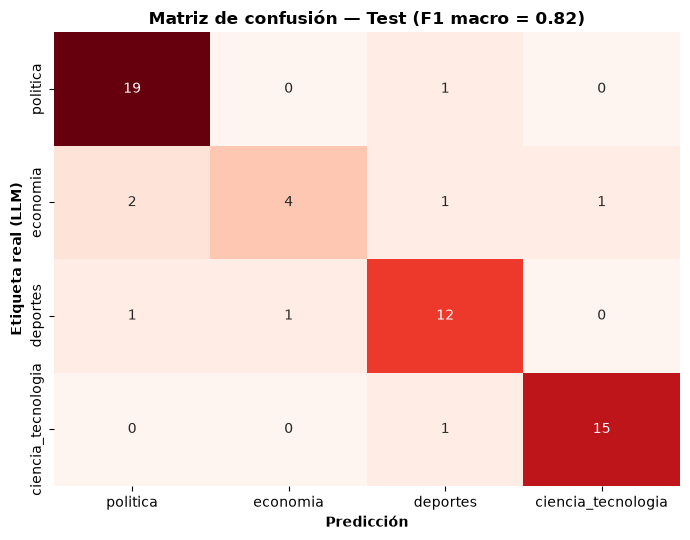

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=CATEGORIAS)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", cbar=False,
            xticklabels=CATEGORIAS, yticklabels=CATEGORIAS, ax=ax)
ax.set_xlabel("Predicción", fontweight="bold")
ax.set_ylabel("Etiqueta real (LLM)", fontweight="bold")
ax.set_title(f"Matriz de confusión — Test (F1 macro = {f1_test:.2f})", fontweight="bold")
plt.tight_layout()
plt.show()

El modelo acierta 51 de 58 titulares en el conjunto de prueba (F1 macro = 0.82). Política, deportes y ciencia y tecnología se clasifican muy bien, mientras que economía es la categoría más débil (4 de 8 aciertos).

Se listan los titulares mal clasificados en el conjunto de prueba, con la etiqueta del LLM, la predicción del modelo y su confianza, ordenados de mayor a menor confianza para revisar primero los errores en los que el modelo estaba más seguro.

In [ ]:
errores = test.loc[y_true != y_pred, ["titular", "etiqueta_llm", "pred", "conf_pred"]]
print(f"Errores: {len(errores)} de {len(test)}")
display(errores.sort_values("conf_pred", ascending=False))

Errores: 8 de 58


,titular,etiqueta_llm,pred,conf_pred
31,Julio Velarde: “En el BCR hay mucha gente que ...,economia,politica,0.848520
36,Ajedrecista peruana Ingrid Aliaga gana siete m...,ciencia_tecnologia,deportes,0.807544
55,Dolor de cabeza en Universitario: Di Benedetto...,politica,deportes,0.793739
32,Menos comida y más cara: El Niño amenaza los a...,economia,ciencia_tecnologia,0.540620
11,“Grand Theft Auto VI” lanza un tráiler con una...,economia,deportes,0.532591
6,"Pablo Nano, gerente de Estudios Económicos de ...",economia,politica,0.429019
51,Mallplaza inaugura su primer Premium Outlets e...,deportes,economia,0.370852
25,Infracon Perú 2026 se inaugura en el Valle Sag...,deportes,politica,0.326072


Se calcula el accuracy del modelo comparando sus predicciones con la sección original de cada noticia.

In [ ]:
print(f"Accuracy vs. sección original: {accuracy_score(test['etiqueta'], y_pred):.2f}")

Accuracy vs. sección original: 0.83


### Reflexión por categoría

**Resultados en test:** Accuracy = 0.86 | F1 Macro = 0.82 | Zero-shot (línea base) = 0.64

- **Mejor desempeño: ciencia_tecnologia (F1 = 0.94).** Acierta 15 de 16 titulares. Su vocabulario
  (ciencia, salud, tecnología, espacio) es distintivo y se cruza poco con las demás categorías.
- **Peor desempeño: economía (F1 = 0.62).** Solo 4 de 8 titulares bien clasificados (recall = 0.50).
  Comparte actores y vocabulario con política (ministros, MEF, Congreso, presupuesto), así que muchos
  titulares son temáticamente ambiguos. Incluso al momento de hacer la auditoría humana, se encontró esta dificultad. Por ejemplo, el titular "Julio Velarde: "En el BCR hay mucha gente que puede sustituirme, pero no cualquiera tampoco" fue etiquetado como economía por el LLM y el modelo lo predijo como política. Su ambiguedad recae en que BCR es materia económica, mientras que la designación/sustitución son actos políticos. 


## 6. Comparativa y decisión

In [11]:
llm = pd.read_csv("datos/etiquetas_llm.csv")
noticias = pd.read_csv("datos/noticias.csv")
llm_vs_seccion = noticias.merge(llm[["titular", "etiqueta_llm"]], on="titular").drop_duplicates("titular")

comparativa = pd.DataFrame([
    {   "Modelo": "Zero-shot (BETO-XNLI)",
        "Evaluado en": "Muestra 40",
        "Referencia": "Sección original",
        "Accuracy": 0.65,
        "F1 macro": 0.64,
    },
    {   "Modelo": "LLM débil (Qwen2.5-1.5B)",
        "Evaluado en": "Dataset completo (383)",
        "Referencia": "Sección original",
        "Accuracy": accuracy_score(llm_vs_seccion["etiqueta"], llm_vs_seccion["etiqueta_llm"]),
        "F1 macro": f1_score(llm_vs_seccion["etiqueta"], llm_vs_seccion["etiqueta_llm"], average="macro"),
    },
    {   "Modelo": "Fine-tuned (BETO)",
        "Evaluado en": "Test (58)",
        "Referencia": "Etiqueta LLM",
        "Accuracy": accuracy_score(test["etiqueta_llm"], test["pred"]),
        "F1 macro": f1_score(test["etiqueta_llm"], test["pred"], average="macro"),
    },
    {   "Modelo": "Fine-tuned (BETO)",
        "Evaluado en": "Test (58)",
        "Referencia": "Sección original",
        "Accuracy": accuracy_score(test["etiqueta"], test["pred"]),
        "F1 macro": f1_score(test["etiqueta"], test["pred"], average="macro"),
    },
]).round(2)

comparativa["Parámetros"] = ["~110M", "~1 500M", "~110M", "~110M"]
comparativa["Costo / latencia"] = [
    "4 pasadas por titular (1 por categoría)",
    "~68 ms/titular en GPU (383 en 26 s); requiere GPU en la práctica",
    "1 pasada por titular; corre en CPU",
    "1 pasada por titular; corre en CPU",
]
display(comparativa)

,Modelo,Evaluado en,Referencia,Accuracy,F1 macro,Parámetros,Costo / latencia
0,Zero-shot (BETO-XNLI),Muestra 40,Sección original,0.65,0.64,~110M,4 pasadas por titular (1 por categoría)
1,LLM débil (Qwen2.5-1.5B),Dataset completo (383),Sección original,0.78,0.77,~1 500M,~68 ms/titular en GPU (383 en 26 s); requiere ...
2,Fine-tuned (BETO),Test (58),Etiqueta LLM,0.86,0.82,~110M,1 pasada por titular; corre en CPU
3,Fine-tuned (BETO),Test (58),Sección original,0.83,0.80,~110M,1 pasada por titular; corre en CPU


### Comparativa y decisión

| Modelo | F1 macro | Referencia | Costo / latencia |
|---|---|---|---|
| Zero-shot (BETO-XNLI) | 0.64 | Sección (40) | Medio: 4 inferencias por titular |
| LLM débil (Qwen 1.5B) | 0.77 | Sección (383) · auditoría 18/20 | Alto: modelo de 1.5B, ~68 ms/titular en GPU |
| Fine-tuned (BETO) | 0.82 / 0.80 | Etiqueta LLM / Sección (test) | Bajo: 1 inferencia, corre en CPU |

**Decisión: Transformer fine-tuned (BETO).**

- **Precisión:** supera claramente al zero-shot (0.64) e incluso al LLM que lo etiquetó. Medidos
  contra la sección original sobre el mismo test de 58 titulares, el fine-tuned obtiene F1 0.80 y
  el LLM 0.77. Al entrenar con cientos de ejemplos, el modelo generaliza los patrones dominantes y
  corrige parte del ruido de las etiquetas individuales del LLM.
- **Costo computacional:** tiene ~14 veces menos parámetros que Qwen. Corre en CPU, así que se
  despliega gratis en Streamlit Cloud. El LLM necesita GPU para ser práctico.
- **Latencia:** hace una sola pasada por titular, contra 4 del zero-shot (una por categoría) y el
  prompt largo del LLM sobre un modelo 14 veces más grande.
